In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import os
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('/content/drive/MyDrive/cars_clean.csv')

In [3]:
df.shape

(3981, 12)

In [4]:
"Number of columns:", df.shape[1]

('Number of columns:', 12)

In [5]:
"Numeric columns:", df.select_dtypes(include=np.number).columns.tolist()

('Numeric columns:', ['model_year', 'milage', 'price'])

In [6]:
"Text columns:", df.select_dtypes(include='object').columns.tolist()

('Text columns:',
 ['brand',
  'model',
  'fuel_type',
  'engine',
  'transmission',
  'ext_col',
  'int_col',
  'accident',
  'clean_title'])

In [7]:
target_column = 'price'
"Target column:", target_column

('Target column:', 'price')

<div dir="ltr">

### Initial Feature Examination

The cleaned dataset contains twelve columns. Three numerical columns include model year, mileage, and price. The nine text columns include brand, model, fuel type, engine, transmission, exterior color, interior color, accident history, and title status. The target column of this project is price.

**Which columns cannot be directly used in a machine learning model?**

All nine text columns cannot be used directly because machine learning models work with numerical values. Among these columns, engine and transmission have a more complex structure because they are not only textual but also contain heterogeneous and combined information that requires separate feature extraction rather than simple numerical encoding. The other text columns, such as brand and fuel type, are categorical and can be converted into numerical values using encoding methods.

</div>

In [8]:
df['engine'].unique()[:15]

array(['300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability',
       '3.8L V6 24V GDI DOHC', '3.5 Liter DOHC',
       '354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid',
       '2.0L I4 16V GDI DOHC Turbo', '2.4 Liter',
       '292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel',
       '282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel',
       '311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel',
       '534.0HP Electric Motor Electric Fuel System', 'V6',
       '715.0HP 5.2L 12 Cylinder Engine Gasoline Fuel',
       '382.0HP 3.0L Straight 6 Cylinder Engine Gasoline Fuel',
       '400.0HP 3.0L V6 Cylinder Engine Gasoline Fuel',
       '2.0 Liter Supercharged'], dtype=object)

In [9]:
def extract_horsepower(text):
    match = re.search(r'(\d+\.?\d*)\s*HP', text)
    return float(match.group(1)) if match else np.nan

def extract_engine_size(text):
    match = re.search(r'(\d+\.?\d*)\s*(?:L\b|Liter)', text)
    return float(match.group(1)) if match else np.nan

def extract_engine_type(text):
    if 'Electric Motor' in text:
        return 'Electric'
    match = re.search(r'(V\d+|I\d+|Straight\s?\d+)', text)
    if match:
        return match.group(1)
    match2 = re.search(r'(\d+)\s*Cylinder', text)
    if match2:
        return match2.group(1) + ' Cylinder'
    return 'Other'

In [10]:
df['horsepower'] = df['engine'].apply(extract_horsepower)
df['engine_size'] = df['engine'].apply(extract_engine_size)
df['engine_type'] = df['engine'].apply(extract_engine_type)

In [11]:
df[['engine', 'horsepower', 'engine_size', 'engine_type']].head(10)

,engine,horsepower,engine_size,engine_type
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,300.0,3.7,V6
1,3.8L V6 24V GDI DOHC,NaN,3.8,V6
2,3.5 Liter DOHC,NaN,3.5,Other
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,354.0,3.5,V6
4,2.0L I4 16V GDI DOHC Turbo,NaN,2.0,I4
5,2.4 Liter,NaN,2.4,Other
6,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,292.0,2.0,4 Cylinder
7,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,282.0,4.4,8 Cylinder
8,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,311.0,3.5,V6
9,534.0HP Electric Motor Electric Fuel System,534.0,NaN,Electric


<div dir="ltr">

### Feature Extraction from the Engine Column

Using Regular Expressions, three new features were extracted from the `engine` column: engine power measured in horsepower (`horsepower`), engine displacement measured in liters (`engine_size`), and engine configuration type (`engine_type`).

Examining the first ten rows showed that the extraction was performed correctly. In cases where engine power was not specified in the original text (such as shorter values like "3.8L V6 24V GDI DOHC"), the `horsepower` value was correctly recorded as NaN. Additionally, for electric engines, since engine displacement in liters is not applicable, the `engine_size` value was correctly recorded as NaN, indicating the logical correctness of the extraction function.

</div>

In [12]:
df['transmission'].unique()

array(['6-Speed A/T', '8-Speed Automatic', 'Automatic', '7-Speed A/T',
       'F', 'A/T', '8-Speed A/T', 'Transmission w/Dual Shift Mode',
       '9-Speed Automatic', '6-Speed M/T', '10-Speed A/T', '9-Speed A/T',
       '5-Speed A/T', '1-Speed A/T', 'Automatic CVT',
       '7-Speed Automatic with Auto-Shift', 'CVT-F', 'M/T',
       '6-Speed Automatic with Auto-Shift', '10-Speed Automatic',
       'CVT Transmission', '4-Speed A/T', '6-Speed Automatic',
       '4-Speed Automatic', '7-Speed M/T',
       '8-Speed Automatic with Auto-Shift', '5-Speed Automatic',
       '8-SPEED AT', '1-Speed Automatic', '5-Speed M/T', '6-Speed Manual',
       'Variable', '2', '7-Speed Manual', 'Automatic, 9-Spd 9G-Tronic',
       'Automatic, 8-Spd',
       'Automatic, 8-Spd Sport w/Sport & Manual Modes', '–',
       'Auto, 6-Spd w/CmdShft', 'Transmission Overdrive Switch',
       '7-Speed Automatic', 'Automatic, 8-Spd PDK Dual-Clutch',
       'Automatic, 8-Spd M STEPTRONIC w/Drivelogic, Sport & Manual Modes

In [13]:
def clean_transmission(text):
    text_lower = str(text).lower()

    if 'dual-clutch' in text_lower or 'dual shift' in text_lower or 'dct' in text_lower:
        return 'Dual Shift'

    if 'cvt' in text_lower:
        return 'CVT'

    if 'manual' in text_lower or 'm/t' in text_lower:
        return 'Manual'

    if 'automatic' in text_lower or 'a/t' in text_lower or 'auto' in text_lower:
        return 'Automatic'

    return 'Other'

df['transmission_clean'] = df['transmission'].apply(clean_transmission)

df['transmission_clean'].value_counts()

,count
transmission_clean,
Automatic,3087
Dual Shift,399
Manual,370
CVT,100
Other,25


<div dir="ltr">

### Standardization of the Transmission Column

The values in the `transmission` column, which were highly inconsistent and unstructured (with more than sixty unique values), were divided into five standardized categories based on keywords found in the text: Automatic, Manual, CVT, Dual Shift, and Other. The Automatic category has the highest frequency, with 3,087 vehicles, which is reasonable given the widespread use of automatic transmissions in modern cars. The Dual Shift category, with 399 vehicles, and the Manual category, with 370 vehicles, rank next. Only 25 vehicles, representing less than one percent of the data, were classified as Other. This category includes unclear values or values unrelated to transmission type, such as entries consisting of only a single letter or number.

</div>

In [14]:
columns_to_check = ['brand', 'fuel_type', 'accident', 'clean_title', 'engine_type', 'transmission_clean']

for col in columns_to_check:
    print(col, ":", df[col].nunique(), "categories")

brand : 56 categories
fuel_type : 7 categories
accident : 2 categories
clean_title : 2 categories
engine_type : 17 categories
transmission_clean : 5 categories


In [15]:
label_cols = ['brand', 'accident', 'clean_title', 'engine_type']

le = LabelEncoder()
for col in label_cols:
    df[col + '_encoded'] = le.fit_transform(df[col])

onehot_cols = ['fuel_type', 'transmission_clean']
df = pd.get_dummies(df, columns=onehot_cols, prefix=onehot_cols)

df.head()

,brand,model,model_year,milage,engine,transmission,ext_col,int_col,accident,clean_title,...,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_Plug-In Hybrid,fuel_type_not supported,fuel_type_–,transmission_clean_Automatic,transmission_clean_CVT,transmission_clean_Dual Shift,transmission_clean_Manual,transmission_clean_Other
0,Ford,Utility Police Interceptor Base,2013,51000,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,...,False,False,False,False,False,True,False,False,False,False
1,Hyundai,Palisade SEL,2021,34742,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,...,True,False,False,False,False,True,False,False,False,False
2,Lexus,RX 350 RX 350,2022,22372,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Unknown,...,True,False,False,False,False,True,False,False,False,False
3,INFINITI,Q50 Hybrid Sport,2015,88900,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,...,False,True,False,False,False,True,False,False,False,False
4,Audi,Q3 45 S line Premium Plus,2021,9835,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Unknown,...,True,False,False,False,False,True,False,False,False,False


In [16]:
print([col for col in df.columns if 'encoded' in col or 'fuel_type_' in col or 'transmission_clean_' in col])

['brand_encoded', 'accident_encoded', 'clean_title_encoded', 'engine_type_encoded', 'fuel_type_Diesel', 'fuel_type_E85 Flex Fuel', 'fuel_type_Gasoline', 'fuel_type_Hybrid', 'fuel_type_Plug-In Hybrid', 'fuel_type_not supported', 'fuel_type_–', 'transmission_clean_Automatic', 'transmission_clean_CVT', 'transmission_clean_Dual Shift', 'transmission_clean_Manual', 'transmission_clean_Other']


<div dir="ltr">

### Encoding Categorical Data

The main criterion for selecting the encoding method was the number of categories in each column.

**One-Hot Encoding** was used for columns with a small number of categories because it keeps the number of new columns manageable and does not create any artificial order among categories:

- Fuel type (seven categories): There is no natural order among fuel types.
- Standardized transmission type (five categories): There is also no natural order among Automatic, Manual, and CVT.

**Label Encoding** was used for columns with many categories or binary values:

- Brand (56 categories): Using One-Hot Encoding would create 56 new columns and make the dataset excessively wide.
- Engine type (17 categories): For the same reason, Label Encoding was selected.
- Accident history and title status (two categories each): For binary columns, Label Encoding creates a single column with values of 0 and 1, making it equivalent to One-Hot Encoding in terms of the resulting dimensionality.

One limitation of this choice should be noted: Label Encoding creates an artificial numerical order among categories in the brand and engine type columns. This does not cause problems for tree-based models, but it may be misleading for linear models and should be taken into account during the modeling phase.

</div>

In [17]:
df = df.drop(columns=['engine', 'transmission'])

In [18]:
for col in ['model', 'ext_col', 'int_col']:
    print(col, ":", df[col].nunique(), "categories")

model : 1883 categories
ext_col : 312 categories
int_col : 150 categories


In [19]:
df = df.drop(columns=['brand', 'accident', 'clean_title', 'engine_type'])
df = df.drop(columns=['model', 'ext_col', 'int_col'])

In [20]:
df.select_dtypes(include='object').columns.tolist()

[]

<div dir="ltr">

### Removal of Unnecessary Columns

**The `engine` and `transmission` columns:** The useful information from these two columns had already been transferred to new columns (horsepower, engine size, engine type, and standardized transmission type), so the raw columns were removed. Some details, such as whether an engine is turbocharged or supports flexible fuel, are lost in this process, which is acceptable for the purpose of this project.

**The text versions of encoded columns:** The brand, accident history, title status, and engine type columns were removed because their information had already been stored in the new numerical columns.

**The `model`, `ext_col`, and `int_col` columns:** These three columns contain 1,883, 312, and 150 categories, respectively. Using One-Hot Encoding would create thousands of new columns, while Label Encoding would introduce a meaningless numerical order. Given that the dataset contains approximately 3,981 rows, most models appear only once or twice, making it difficult for the model to learn meaningful patterns from them. Therefore, these columns were removed.

</div>

In [21]:
df.shape

(3981, 21)

In [22]:
df.dtypes

,0
model_year,int64
milage,int64
price,float64
horsepower,float64
engine_size,float64
brand_encoded,int64
accident_encoded,int64
clean_title_encoded,int64
engine_type_encoded,int64
fuel_type_Diesel,bool


In [23]:
df.isnull().sum()

,0
model_year,0
milage,0
price,0
horsepower,789
engine_size,216
brand_encoded,0
accident_encoded,0
clean_title_encoded,0
engine_type_encoded,0
fuel_type_Diesel,0


In [24]:
df.head()

,model_year,milage,price,horsepower,engine_size,brand_encoded,accident_encoded,clean_title_encoded,engine_type_encoded,fuel_type_Diesel,...,fuel_type_Gasoline,fuel_type_Hybrid,fuel_type_Plug-In Hybrid,fuel_type_not supported,fuel_type_–,transmission_clean_Automatic,transmission_clean_CVT,transmission_clean_Dual Shift,transmission_clean_Manual,transmission_clean_Other
0,2013,51000,10300.0,300.0,3.7,13,0,1,15,False,...,False,False,False,False,False,True,False,False,False,False
1,2021,34742,38005.0,NaN,3.8,18,0,1,15,False,...,True,False,False,False,False,True,False,False,False,False
2,2022,22372,54598.0,NaN,3.5,26,1,0,11,False,...,True,False,False,False,False,True,False,False,False,False
3,2015,88900,15500.0,354.0,3.5,19,1,1,15,False,...,False,True,False,False,False,True,False,False,False,False
4,2021,9835,34999.0,NaN,2.0,3,1,0,9,False,...,True,False,False,False,False,True,False,False,False,False


<div dir="ltr">

### Final Dataset Examination

The final dataset contains 3,981 rows and 21 columns. No text columns remain, and the columns consist of five original numerical features, four Label Encoding columns, and twelve One-Hot Encoding columns. The One-Hot columns are stored as the `bool` data type.

Regarding missing values, only two columns have this issue: the `horsepower` column, with 789 missing values (approximately 20%), and the `engine_size` column, with 216 missing values (approximately 5%). This is because engine power was not specified for some vehicles in the original `engine` column, and electric engines do not have a displacement measured in liters.

**Is the dataset now ready for model training?**

Not completely. All features have been converted to numerical values, but the missing values in these two columns must be handled before training because many models cannot work with missing values. Additionally, the Boolean columns should preferably be converted to 0 and 1. These two steps will be completed before saving the final dataset.

</div>

In [25]:
corr_cols = ['price', 'milage', 'model_year', 'horsepower', 'engine_size',
             'accident_encoded', 'clean_title_encoded']
corr_matrix = df[corr_cols].corr()
corr_matrix

,price,milage,model_year,horsepower,engine_size,accident_encoded,clean_title_encoded
price,1.000000,-0.527571,0.442392,0.636161,0.205753,0.221916,-0.190033
milage,-0.527571,1.000000,-0.619203,-0.340893,0.086177,-0.298795,0.254429
model_year,0.442392,-0.619203,1.000000,0.305387,-0.124259,0.192959,-0.266315
horsepower,0.636161,-0.340893,0.305387,1.000000,0.636764,0.129621,-0.039351
engine_size,0.205753,0.086177,-0.124259,0.636764,1.000000,-0.014715,0.067489
accident_encoded,0.221916,-0.298795,0.192959,0.129621,-0.014715,1.000000,-0.171998
clean_title_encoded,-0.190033,0.254429,-0.266315,-0.039351,0.067489,-0.171998,1.000000


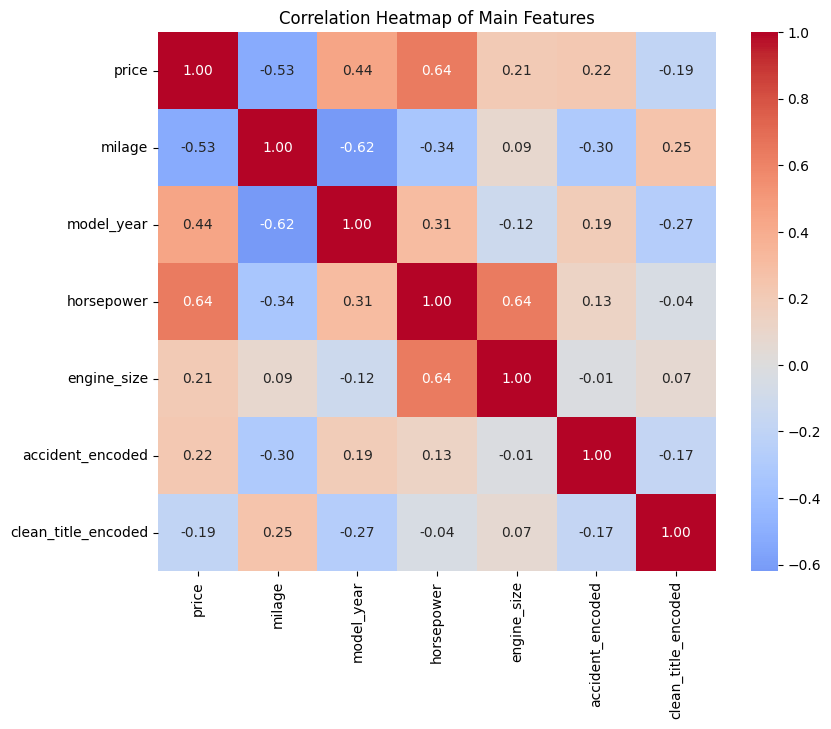

In [26]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Main Features')
plt.show()

<div dir="ltr">

### Feature Selection

**Which feature has the strongest correlation with price?**

Horsepower has the strongest correlation with price, with a correlation coefficient of 0.64, indicating a positive relationship. This means that more powerful vehicles tend to be more expensive. Mileage comes next, with a correlation coefficient of -0.53 (negative relationship), followed by model year, with a coefficient of 0.44 (positive relationship). These results are consistent with the visual analysis conducted in Phase 1. Engine size (0.21), accident history (0.22), and title status (-0.19) have weaker correlations with price.

**Is there a high correlation between any two other features?**

Yes, two cases can be observed. First, mileage and model year have a correlation of -0.62, which is reasonable because older vehicles have generally accumulated more mileage. Second, horsepower and engine size have a correlation of 0.64 because larger engines generally produce more power. These correlations indicate that each pair of features contains some overlapping information, which may cause problems for linear models due to multicollinearity.

**Conclusion and Limitations**

No feature has a very high correlation (above 0.8) with price, indicating that price depends on a combination of features rather than being explained by a single feature. Two points should also be considered. First, the correlation coefficient measures only linear relationships, whereas the Phase 1 analysis showed that the relationship between mileage and price resembles an exponential decay curve. Therefore, the correlation coefficient of -0.53 may underestimate the actual strength of this relationship. Second, correlation does not imply causation. Additionally, title status is encoded as 0 for "Unknown" and 1 for "Yes." Therefore, its negative correlation means that vehicles with unknown title status tend to be more expensive in this dataset. This should not be interpreted as evidence that having a clean title reduces a vehicle's price.

</div>

In [27]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())
df['engine_size'] = df['engine_size'].fillna(df['engine_size'].median())

In [28]:
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

In [29]:
print("Total missing values:", df.isnull().sum().sum())
print(df.dtypes.value_counts())

Total missing values: 0
int64      18
float64     3
Name: count, dtype: int64


In [32]:
os.makedirs('data', exist_ok=True)
df.to_csv('data/cars_features.csv', index=False)
print("Saved successfully. Final shape:", df.shape)

Saved successfully. Final shape: (3981, 21)
